# YOLO — Multi-Object Detection on Our 20-Class Image Dataset

### Deep Learning · Discriminative Project

Following the structure of the YOLO quick demo, applied to **our own dataset**:

1. **Prepare** the data: load our 500 combined images (already split into train / val / test), write the dataset YAML, check the labels
2. **Test** a pretrained detector and see what `conf` and `iou` do
3. **Train** YOLOv8 on our 20 classes
4. **Score** it with IoU / mAP on val and test, and **report the ID and location of every object**

**Before you run it**

* Open this notebook *from the project folder*, next to the `combined_dataset/` folder
  (the one with `images/` and `labels/` made by `Data_Augmentation_Yolo.ipynb`).
  Each combined image is a 640 × 640 white canvas with 2–4 of our 224 × 224 single-object
  photos pasted on it (randomly rotated, flipped, brightened, blurred or zoomed).
  That notebook first splits the single-object photos of every class **80 / 10 / 10**, then
  builds 400 train, 50 val and 50 test images, each only from photos of its own split.
* Install the one requirement once: `pip install "ultralytics>=8.4"` (or run the cell below).
* The first run downloads `yolov8n.pt` (about 6 MB), so be online for that.

**Class IDs:** one per folder in `../data`, in sorted order, the same order as our
classification notebooks:

| ID | class | ID | class | ID | class | ID | class |
|---|---|---|---|---|---|---|---|
| 0 | OBJ000 | 5 | OBJ007 | 10 | OBJ123 | 15 | OBJ529 |
| 1 | OBJ001 | 6 | OBJ011 | 11 | OBJ125 | 16 | OBJ608 |
| 2 | OBJ002 | 7 | OBJ070 | 12 | OBJ201 | 17 | OBJ666 |
| 3 | OBJ004 | 8 | OBJ108 | 13 | OBJ222 | 18 | OBJ777 |
| 4 | OBJ006 | 9 | OBJ111 | 14 | OBJ523 | 19 | OBJ916 |

In [1]:
from ultralytics import YOLO
from pathlib import Path
from IPython.display import display
import os, random, shutil, cv2, torch
import numpy as np
import pandas as pd, matplotlib.pyplot as plt

pd.set_option("display.precision", 3)

# Use the GPU if there is one: NVIDIA (cuda), Apple silicon (mps), otherwise the CPU.
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

SRC_DIR    = Path("combined_dataset")             # made by Data_Augmentation_Yolo.ipynb, already split
DATA_DIR   = Path("datasets/objects20")           # the folder Ultralytics will read
DATA_YAML  = DATA_DIR / "objects20.yaml"

# Same class order as Data_Augmentation_Yolo.ipynb: sorted folders in ../data, 'images_' prefix removed
NAMES  = dict(enumerate(sorted(f.replace("images_", "").strip() for f in os.listdir("../data")
                               if os.path.isdir(os.path.join("../data", f)))))
COLORS = {i: tuple(int(v) for v in np.random.default_rng(i).integers(0, 256, 3)) for i in NAMES}   # BGR

print("device:", DEVICE)

def show(result, ax=None, title=""):
    # result.plot() returns the image with boxes drawn on it (in OpenCV's BGR colour order)
    if ax is None:
        ax = plt.subplots(figsize=(8, 6))[1]
    ax.imshow(result.plot()[:, :, ::-1])
    ax.set_title(title, fontsize=10)
    ax.axis("off")

def draw_gt(img_path, split):
    # draw the TRUE boxes from the YOLO label file on an image (returns an RGB image)
    img = cv2.imread(str(img_path)); h, w = img.shape[:2]
    label_file = DATA_DIR / "labels" / split / f"{Path(img_path).stem}.txt"
    for line in label_file.read_text().splitlines():
        if not line.strip():
            continue
        c, cx, cy, bw, bh = line.split(); c = int(c)
        cx, cy, bw, bh = float(cx) * w, float(cy) * h, float(bw) * w, float(bh) * h
        p1, p2 = (int(cx - bw / 2), int(cy - bh / 2)), (int(cx + bw / 2), int(cy + bh / 2))
        cv2.rectangle(img, p1, p2, COLORS[c], 2)
        cv2.putText(img, NAMES[c], (p1[0], max(p1[1] - 6, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, COLORS[c], 2)
    return img[:, :, ::-1]

device: mps


---
## 1. Prepare the dataset

Ultralytics wants the layout `images/{train,val,test}` and `labels/{train,val,test}`, plus a
YAML file that lists the folders and class names. The split was already made **before**
combining: `Data_Augmentation_Yolo.ipynb` split the single-object photos of every class
80 / 10 / 10 (seed 42, list saved in `combined_dataset/source_split.csv`) and built each split's
combined images only from that split's photos. So no photo is shared between train, val and
test, and here we only copy the three splits over.
Each `.txt` label file already has the format YOLO expects: `class_id  cx  cy  w  h`, all
normalised to 0–1.

In [2]:
# The augmentation notebook already split the photos, so we keep its train / val / test as they are
splits = {split: sorted(p.stem for p in (SRC_DIR / split / "images").glob("*.jpg"))
          for split in ("train", "val", "test")}

if DATA_DIR.exists():
    shutil.rmtree(DATA_DIR)                     # start clean so old files never mix in
for split, names in splits.items():
    (DATA_DIR / "images" / split).mkdir(parents=True)
    (DATA_DIR / "labels" / split).mkdir(parents=True)
    for s in names:
        shutil.copy(SRC_DIR / split / "images" / f"{s}.jpg", DATA_DIR / "images" / split / f"{s}.jpg")
        shutil.copy(SRC_DIR / split / "labels" / f"{s}.txt", DATA_DIR / "labels" / split / f"{s}.txt")

# Same format as a standard Ultralytics dataset YAML. No 'path:' key, so the folders
# are resolved relative to this file.
DATA_YAML.write_text(
    "train: images/train\n"
    "val: images/val\n"
    "test: images/test\n"
    "names:\n" + "".join(f"  {i}: {name}\n" for i, name in NAMES.items())
)
print(DATA_YAML.read_text())

train: images/train
val: images/val
test: images/test
names:
  0: OBJ000
  1: OBJ001
  2: OBJ002
  3: OBJ004
  4: OBJ006
  5: OBJ007
  6: OBJ011
  7: OBJ070
  8: OBJ108
  9: OBJ111
  10: OBJ123
  11: OBJ125
  12: OBJ201
  13: OBJ222
  14: OBJ523
  15: OBJ529
  16: OBJ608
  17: OBJ666
  18: OBJ777
  19: OBJ916



Two quick checks before training. First, **count the boxes per class in each split**, so we
know the classes are balanced and every class appears in val and test. Second, **make sure
every label is valid** (class id in 0–19 and all numbers between 0 and 1). A bad label file is
one of the most common reasons a detector trains badly.

In [3]:
rows, problems = {}, 0
for split in splits:
    counts = dict.fromkeys(NAMES.values(), 0)
    for f in (DATA_DIR / "labels" / split).glob("*.txt"):
        for line in f.read_text().splitlines():
            if not line.strip():
                continue
            c, *xywh = line.split()
            if int(c) not in NAMES or not all(0 <= float(v) <= 1 for v in xywh):
                problems += 1
            else:
                counts[NAMES[int(c)]] += 1
    rows[split] = {"images": len(splits[split]), **counts}

print("invalid label lines:", problems)
pd.DataFrame(rows).T

invalid label lines: 0


,images,OBJ000,OBJ001,OBJ002,OBJ004,OBJ006,OBJ007,OBJ011,OBJ070,OBJ108,...,OBJ123,OBJ125,OBJ201,OBJ222,OBJ523,OBJ529,OBJ608,OBJ666,OBJ777,OBJ916
train,400,67,64,67,75,50,63,62,56,56,...,70,57,61,62,68,59,53,57,66,62
val,50,11,8,5,5,8,7,6,10,10,...,6,5,7,10,4,11,8,8,11,7
test,50,7,5,4,8,10,9,5,10,7,...,8,7,10,5,8,4,11,12,5,4


Now **look at the true boxes** on a few training images. If a box is in the wrong place or
carries the wrong class here, the problem is in the data, not in the model.

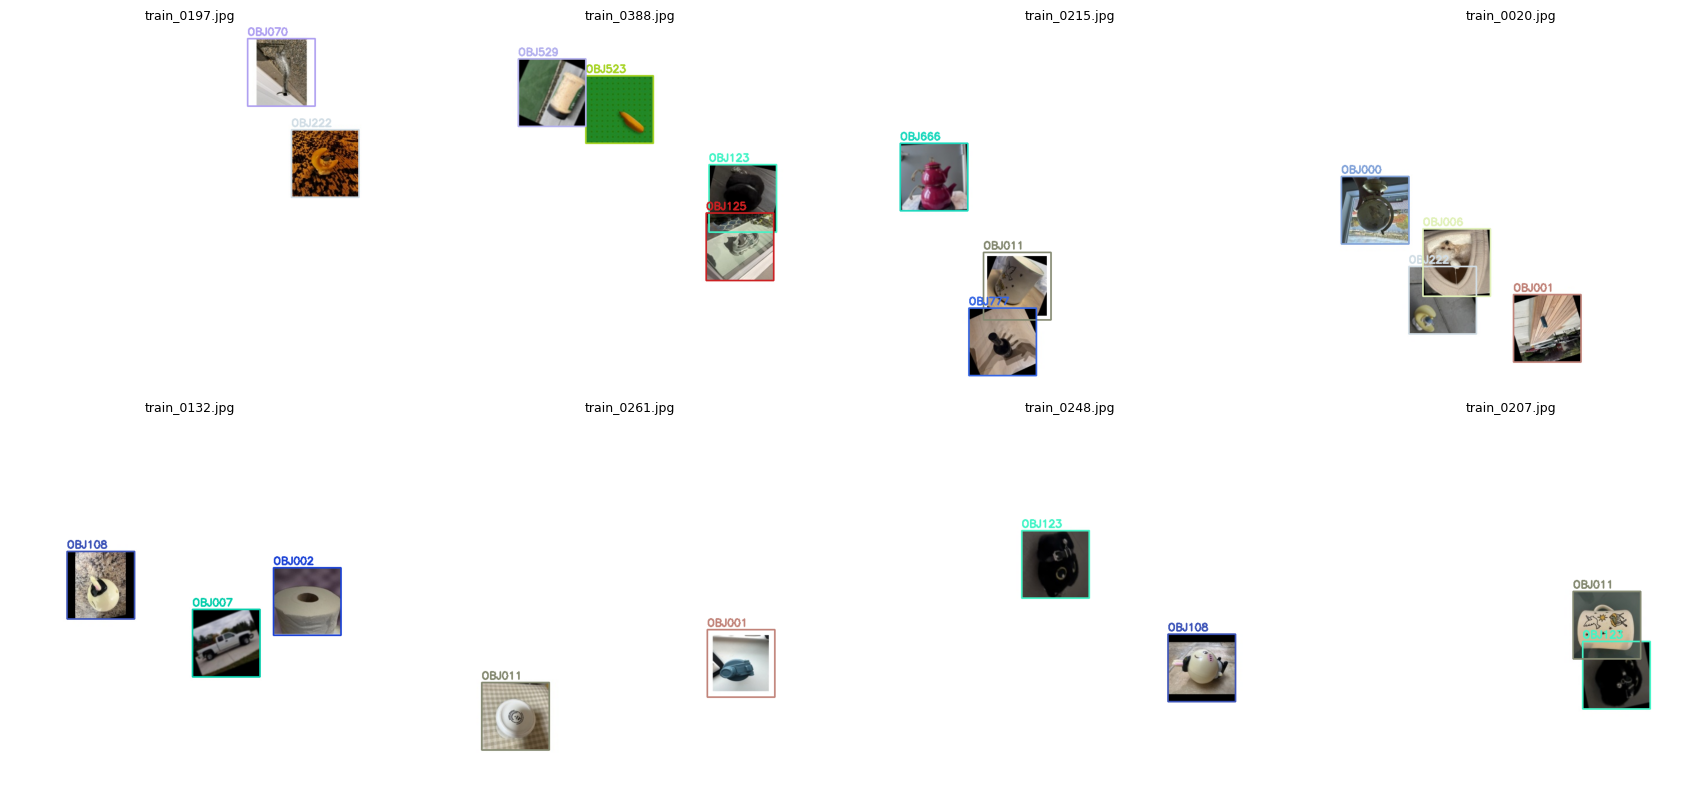

In [4]:
train_images = sorted((DATA_DIR / "images" / "train").glob("*.jpg"))
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, p in zip(axes.flat, random.Random(0).sample(train_images, 8)):
    ax.imshow(draw_gt(p, "train")); ax.set_title(p.name, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

---
## 2. Test a pretrained detector

`yolov8n.pt` is the smallest YOLOv8, trained on the 80 everyday classes of **COCO**. COCO has
classes, but they are not our classes: a few of our objects (a dog, a car, a giraffe) have a
COCO name, most do not, and none of them uses our `OBJxxx` IDs. Before training anything,
let's see what it already knows about our images.

image 1/1 /Users/garimadaryani/Documents/NEU/image-classification-project/Discriminative Porject - Yolo/datasets/objects20/images/test/test_0000.jpg: 640x640 1 truck, 5.0ms


Speed: 623.2ms preprocess, 5.0ms inference, 21.1ms postprocess per image at shape (1, 3, 640, 640)


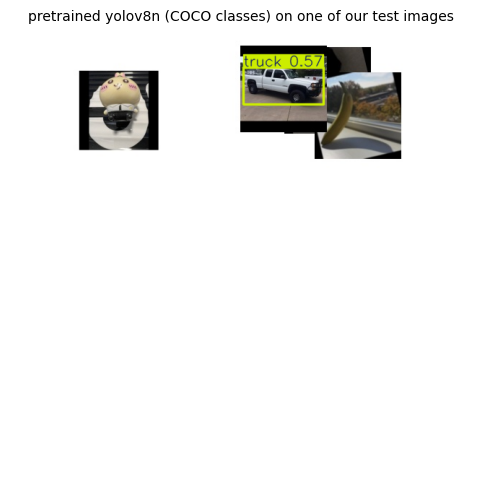

truck      confidence 0.57   corners (x1, y1, x2, y2) = [        324          53         435         104]


In [5]:
model = YOLO("yolov8n.pt")

test_images = sorted((DATA_DIR / "images" / "test").glob("*.jpg"))
result = model(test_images[0], conf=0.25, iou=0.7, device=DEVICE)[0]
show(result, title="pretrained yolov8n (COCO classes) on one of our test images")
plt.show()

for box in result.boxes:
    print(f"{result.names[int(box.cls)]:10s} confidence {float(box.conf):.2f}   "
          f"corners (x1, y1, x2, y2) = {box.xyxy[0].cpu().numpy().round(0)}")

The network proposes thousands of candidate boxes. Two thresholds decide which ones you see:

| argument | what it does | too low | too high |
|---|---|---|---|
| `conf` | drops boxes whose confidence is below it | clutter, false alarms | real objects missed |
| `iou` | **NMS**: if two boxes of the same class overlap more than this, keep only the more confident one | neighbouring objects merged | duplicate boxes survive |

Below, three settings on the test image that has the most objects.

test_0000.jpg: 4 labelled objects


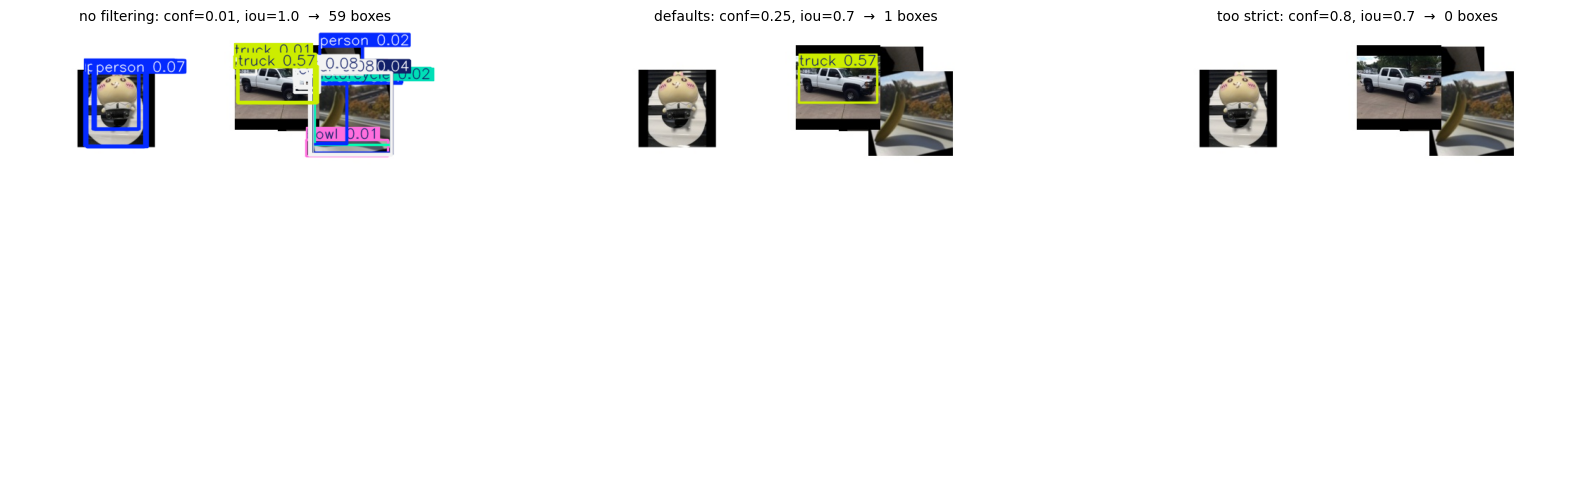

In [6]:
def n_objects(img):   # number of labelled objects = lines in the image's label file
    return len((DATA_DIR / "labels" / "test" / f"{img.stem}.txt").read_text().splitlines())

busy = max(test_images, key=n_objects)
print(f"{busy.name}: {n_objects(busy)} labelled objects")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (c, i, name) in zip(axes, [(0.01, 1.0, "no filtering"),
                                   (0.25, 0.7, "defaults"),
                                   (0.80, 0.7, "too strict")]):
    r = model(busy, conf=c, iou=i, device=DEVICE, verbose=False, max_det=1000)[0]
    show(r, ax, title=f"{name}: conf={c}, iou={i}  →  {len(r.boxes)} boxes")
plt.tight_layout(); plt.show()

Compare this with the green boxes you saw in section 1. The pretrained model only speaks COCO,
so look for objects it misses or names wrongly. That is why we **fine-tune** it on our 20
classes.

---
## 3. Train on our dataset

**Fine-tuning** starts from the COCO weights, so the network already knows edges, textures
and object shapes. Only the last layer is rebuilt, because 80 classes become 20.

Our dataset is much smaller than a typical one (400 training images, about 60 boxes per class), so we train for **50
epochs** instead of a handful. Our canvases are 640 × 640, exactly `imgsz=640`, so no padding is needed.
Ultralytics also applies its own augmentation while training (mosaic, colour jitter,
horizontal flip), on top of the augmentation we did when creating the images.

> On an Apple M2 (`mps`) this takes about 20 minutes. If it is too slow on your machine,
> lower `epochs` to 30. Training also stops early if val mAP does not improve for 20 epochs
> (`patience=20`).

In [7]:
model = YOLO("yolov8n.pt")
model.train(data=str(DATA_YAML), epochs=50, imgsz=640, batch=16, patience=20,
            device=DEVICE, name="objects20", exist_ok=True, seed=42)

run = Path(model.trainer.save_dir)          # e.g. runs/detect/objects20
print("results saved in", run)

New https://pypi.org/project/ultralytics/8.4.190 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.188 🚀 Python-3.10.19 torch-2.14.1 MPS (Apple M2)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=datasets/objects20/objects20.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=objects20, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=20, perspective=0.0, plots=True, pose

Overriding model.yaml nc=80 with nc=20



                   from  n    params  module                                       arguments                     


...

                OBJ777         11         11      0.917      0.636      0.898      0.898


                OBJ916          7          7       0.87          1      0.995      0.838


Speed: 0.1ms preprocess, 11.8ms inference, 0.0ms loss, 1.5ms postprocess per image


Results saved to /Users/garimadaryani/Documents/NEU/image-classification-project/Discriminative Porject - Yolo/runs/detect/objects20


results saved in /Users/garimadaryani/Documents/NEU/image-classification-project/Discriminative Porject - Yolo/runs/detect/objects20


Ultralytics saves its own plots in the run folder. `results.png` shows the losses and the
validation metrics after every epoch. The box, class and DFL losses should go **down**, and
mAP should go **up**.

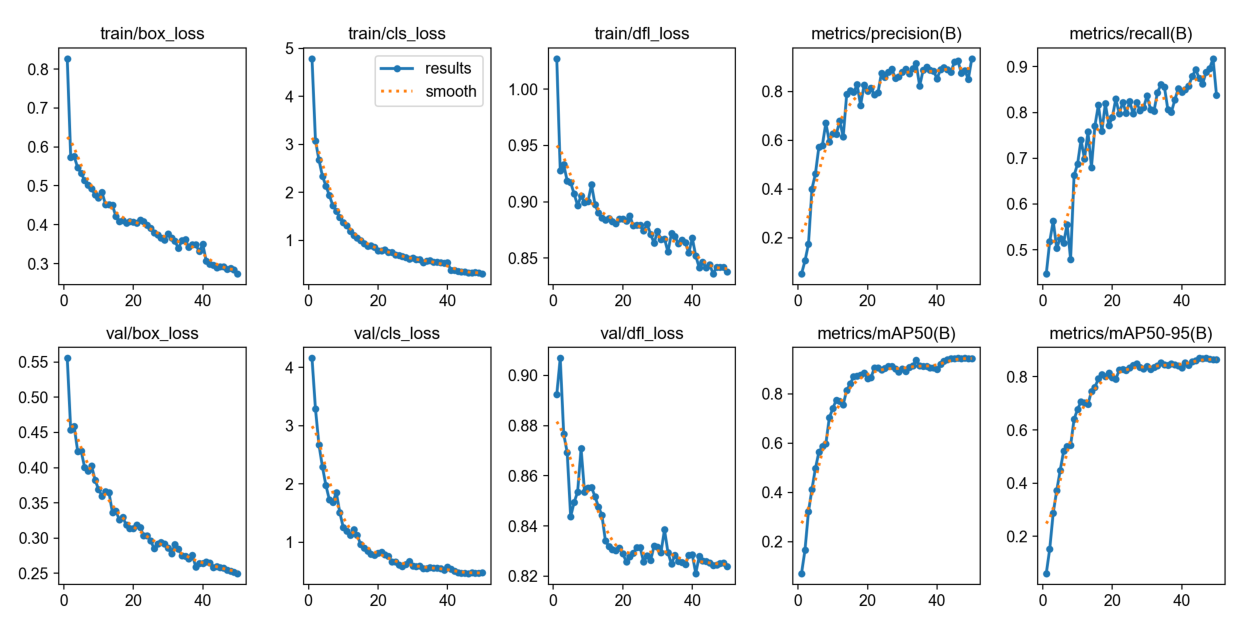

In [8]:
plt.figure(figsize=(16, 8))
plt.imshow(plt.imread(run / "results.png")); plt.axis("off"); plt.show()

It also saves a batch of validation images twice: once with the **true** boxes and once with
the model's **predicted** boxes.

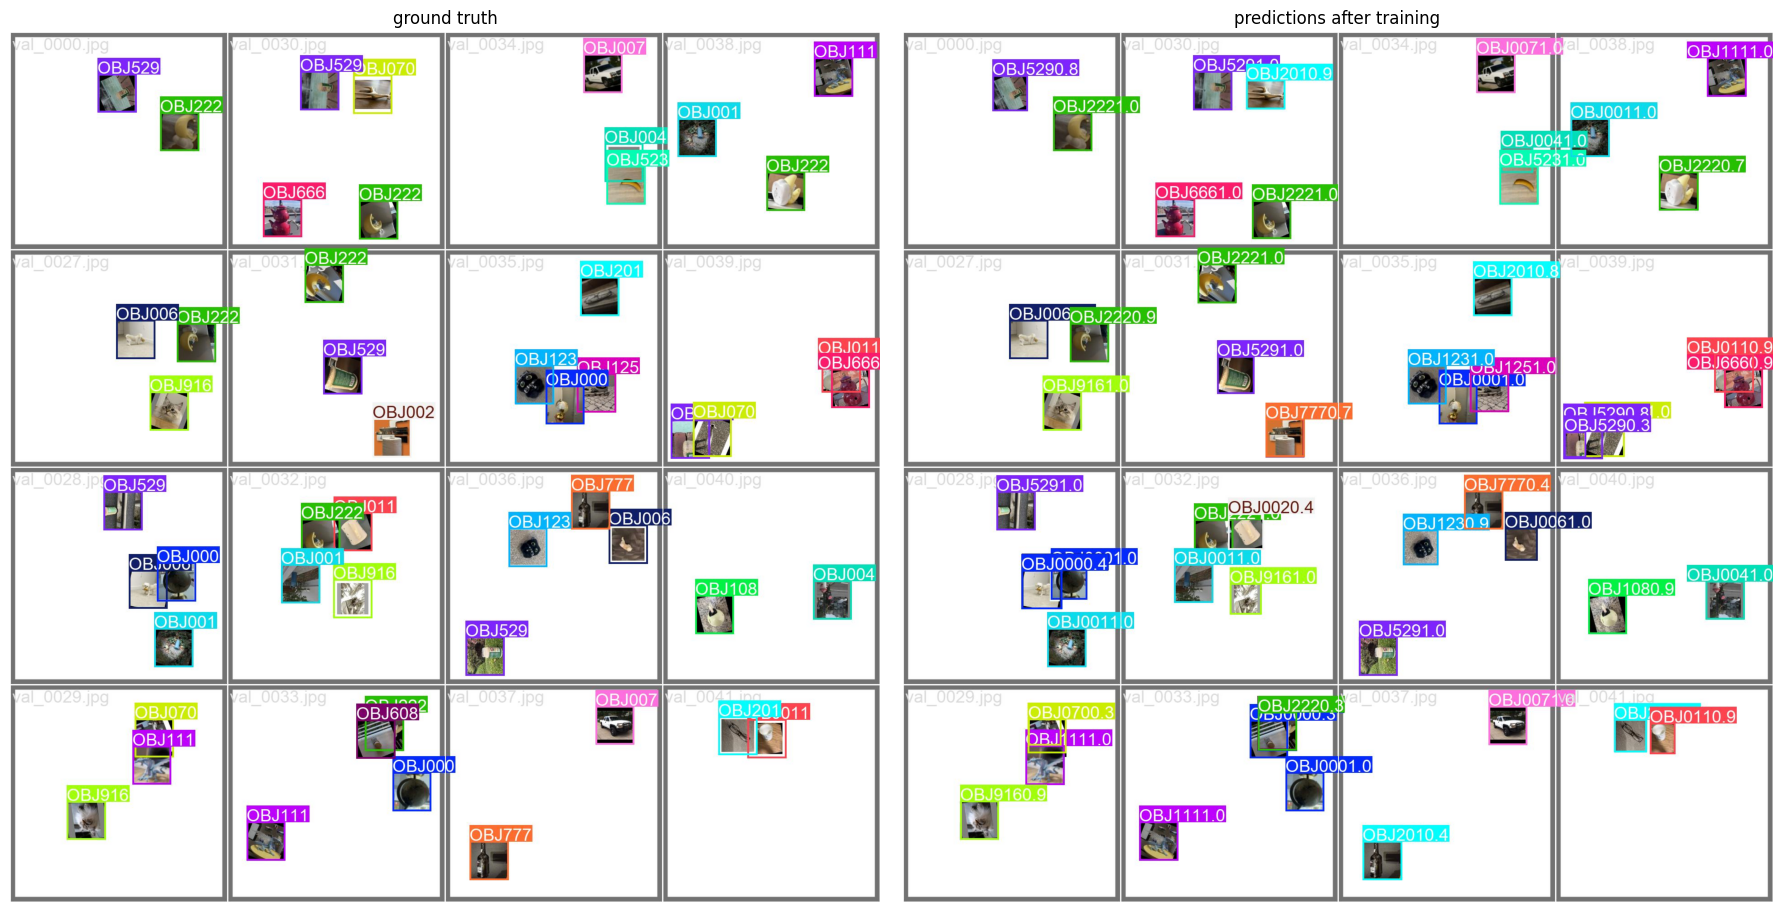

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 9))
for ax, f, title in zip(axes, ("val_batch0_labels.jpg", "val_batch0_pred.jpg"),
                        ("ground truth", "predictions after training")):
    ax.imshow(plt.imread(run / f)); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

The **confusion matrix** shows which classes get mixed up. Each row is the true class, each
column the predicted one, and the last row / column is "background" (a missed object or a box
on nothing). A good model has a strong diagonal.

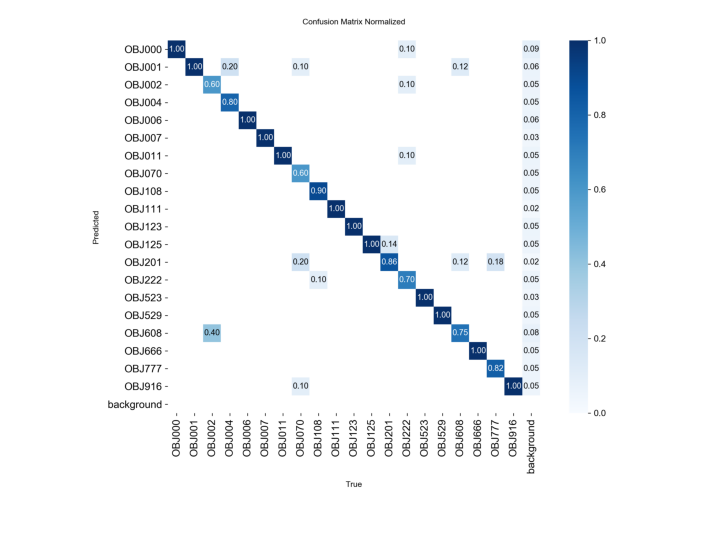

In [10]:
plt.figure(figsize=(9, 8))
plt.imshow(plt.imread(run / "confusion_matrix_normalized.png")); plt.axis("off"); plt.show()

---
## 4. Score the detector and report every object

**IoU** measures how well a predicted box matches a true box:

$$\text{IoU} = \frac{\text{area of overlap}}{\text{area of union}}$$

A prediction counts as correct if its IoU with a true box **of the same class** is at least a
threshold *t*. Counting correct and wrong predictions gives **precision** (how many
predictions were right) and **recall** (how many objects were found). **mAP** summarises
both in one number between 0 and 1.

| metric | threshold *t* | question it answers |
|---|---|---|
| **mAP50** | 0.5 | did it find the object? |
| **mAP50-95** | average over 0.50 … 0.95 | did it find it **and** draw a tight box? |

**val** is for decisions made during training, such as which epoch to keep. **test** is used
once, at the end, as the score on images the model never influenced.

In [11]:
trained = YOLO(run / "weights" / "best.pt")     # the best epoch

overall, per_class = {}, {}
for split in ("val", "test"):
    m = trained.val(data=str(DATA_YAML), split=split, imgsz=640, device="cpu",
                    plots=False, verbose=False)
    overall[split] = {"mAP50": m.box.map50, "mAP50-95": m.box.map,
                      "precision": m.box.mp, "recall": m.box.mr}
    per_class[split] = {m.names[int(c)]: ap for c, ap in zip(m.box.ap_class_index, m.box.ap50)}

print("Overall"); display(pd.DataFrame(overall).T)
print("mAP50 per class"); display(pd.DataFrame(per_class))

Ultralytics 8.4.188 🚀 Python-3.10.19 torch-2.14.1 CPU (Apple M2)


Model summary (fused): 73 layers, 3,137,324 parameters, 0 gradients, 8.7 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 801.3±193.4 MB/s, size: 27.8 KB)


val: Scanning /Users/garimadaryani/Documents/NEU/image-classification-project/Discriminative Porject - Yolo/datasets/objects20/labels/val.cache... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 16.1Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 25% ━━━───────── 1/4 3.8s/it 1.1s<11.3s

...

Speed: 0.5ms preprocess, 68.3ms inference, 0.0ms loss, 0.4ms postprocess per image


Overall


,mAP50,mAP50-95,precision,recall
val,0.943,0.870,0.922,0.875
test,0.948,0.866,0.885,0.892


mAP50 per class


,val,test
OBJ000,0.995,0.995
OBJ001,0.995,0.770
OBJ002,0.713,0.995
OBJ004,0.962,0.892
OBJ006,0.995,0.938
OBJ007,0.995,0.995
OBJ011,0.972,0.995
OBJ070,0.898,0.986
OBJ108,0.929,0.995
OBJ111,0.995,0.995


**Rule:** *evaluate* at a very low `conf` (that is what `model.val()` does by default, 0.001),
and *deploy* at whatever `conf` your application needs. Next we use `conf=0.25`.

Now the point of the assignment: for every test image, report **the ID and the location of
each object**. Each image below is also saved with its boxes drawn on it.

In [12]:
OUT = run / "test_predictions"
OUT.mkdir(exist_ok=True)

for p in test_images:
    r = trained(p, imgsz=640, conf=0.25, device=DEVICE, verbose=False)[0]
    print(f"\n{p.name}: {len(r.boxes)} object(s) found, {n_objects(p)} labelled")
    for box in r.boxes:
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
        print(f"  id={int(box.cls)} {r.names[int(box.cls)]:7s} conf={float(box.conf):.2f}   "
              f"box (x1, y1, x2, y2) = ({x1:.0f}, {y1:.0f}, {x2:.0f}, {y2:.0f})   "
              f"center = ({(x1 + x2) / 2:.0f}, {(y1 + y2) / 2:.0f})")
    cv2.imwrite(str(OUT / p.name), r.plot())

print("\nannotated images saved in", OUT)


test_0000.jpg: 3 object(s) found, 4 labelled
  id=8 OBJ108  conf=0.97   box (x1, y1, x2, y2) = (96, 59, 206, 168)   center = (151, 113)
  id=5 OBJ007  conf=0.97   box (x1, y1, x2, y2) = (320, 23, 499, 144)   center = (409, 84)
  id=14 OBJ523  conf=0.70   box (x1, y1, x2, y2) = (422, 60, 542, 181)   center = (482, 120)

test_0001.jpg: 5 object(s) found, 4 labelled
  id=18 OBJ777  conf=0.96   box (x1, y1, x2, y2) = (203, 187, 323, 306)   center = (263, 246)
  id=4 OBJ006  conf=0.95   box (x1, y1, x2, y2) = (31, 170, 151, 290)   center = (91, 230)
  id=15 OBJ529  conf=0.58   box (x1, y1, x2, y2) = (201, 383, 322, 503)   center = (261, 443)
  id=17 OBJ666  conf=0.42   box (x1, y1, x2, y2) = (155, 275, 259, 383)   center = (207, 329)
  id=6 OBJ011  conf=0.34   box (x1, y1, x2, y2) = (31, 171, 151, 290)   center = (91, 230)

test_0002.jpg: 2 object(s) found, 2 labelled
  id=3 OBJ004  conf=0.77   box (x1, y1, x2, y2) = (412, 18, 531, 140)   center = (471, 79)
  id=1 OBJ001  conf=0.56   box (


test_0009.jpg: 4 object(s) found, 4 labelled
  id=3 OBJ004  conf=0.98   box (x1, y1, x2, y2) = (53, 61, 164, 173)   center = (108, 117)
  id=9 OBJ111  conf=0.98   box (x1, y1, x2, y2) = (98, 427, 217, 547)   center = (157, 487)
  id=19 OBJ916  conf=0.96   box (x1, y1, x2, y2) = (212, 229, 333, 349)   center = (272, 289)
  id=17 OBJ666  conf=0.95   box (x1, y1, x2, y2) = (217, 490, 338, 610)   center = (278, 550)

test_0010.jpg: 3 object(s) found, 3 labelled
  id=3 OBJ004  conf=0.98   box (x1, y1, x2, y2) = (36, 428, 156, 548)   center = (96, 488)
  id=16 OBJ608  conf=0.98   box (x1, y1, x2, y2) = (207, 89, 327, 209)   center = (267, 149)
  id=1 OBJ001  conf=0.89   box (x1, y1, x2, y2) = (456, 38, 577, 159)   center = (517, 98)

test_0011.jpg: 3 object(s) found, 3 labelled
  id=16 OBJ608  conf=0.99   box (x1, y1, x2, y2) = (472, 82, 592, 203)   center = (532, 143)
  id=5 OBJ007  conf=0.95   box (x1, y1, x2, y2) = (218, 33, 338, 153)   center = (278, 93)
  id=17 OBJ666  conf=0.85   box 


test_0018.jpg: 2 object(s) found, 2 labelled
  id=4 OBJ006  conf=0.93   box (x1, y1, x2, y2) = (43, 403, 164, 524)   center = (104, 463)
  id=14 OBJ523  conf=0.33   box (x1, y1, x2, y2) = (381, 330, 501, 450)   center = (441, 390)

test_0019.jpg: 3 object(s) found, 3 labelled
  id=0 OBJ000  conf=0.98   box (x1, y1, x2, y2) = (376, 486, 496, 605)   center = (436, 546)
  id=16 OBJ608  conf=0.97   box (x1, y1, x2, y2) = (352, 172, 472, 291)   center = (412, 232)
  id=12 OBJ201  conf=0.96   box (x1, y1, x2, y2) = (114, 444, 234, 565)   center = (174, 504)

test_0020.jpg: 2 object(s) found, 2 labelled
  id=15 OBJ529  conf=0.98   box (x1, y1, x2, y2) = (438, 68, 537, 167)   center = (488, 117)
  id=14 OBJ523  conf=0.98   box (x1, y1, x2, y2) = (166, 145, 287, 265)   center = (227, 205)

test_0021.jpg: 3 object(s) found, 3 labelled
  id=1 OBJ001  conf=0.98   box (x1, y1, x2, y2) = (184, 386, 304, 506)   center = (244, 446)
  id=9 OBJ111  conf=0.98   box (x1, y1, x2, y2) = (468, 429, 588, 550


test_0028.jpg: 2 object(s) found, 2 labelled
  id=12 OBJ201  conf=0.97   box (x1, y1, x2, y2) = (199, 197, 320, 317)   center = (260, 257)
  id=18 OBJ777  conf=0.94   box (x1, y1, x2, y2) = (322, 174, 442, 294)   center = (382, 234)

test_0029.jpg: 4 object(s) found, 3 labelled
  id=9 OBJ111  conf=0.97   box (x1, y1, x2, y2) = (94, 34, 214, 154)   center = (154, 94)
  id=8 OBJ108  conf=0.63   box (x1, y1, x2, y2) = (117, 211, 237, 332)   center = (177, 271)
  id=19 OBJ916  conf=0.52   box (x1, y1, x2, y2) = (428, 224, 547, 344)   center = (488, 284)
  id=13 OBJ222  conf=0.40   box (x1, y1, x2, y2) = (116, 211, 237, 331)   center = (177, 271)

test_0030.jpg: 3 object(s) found, 3 labelled
  id=16 OBJ608  conf=0.99   box (x1, y1, x2, y2) = (65, 156, 184, 275)   center = (125, 215)
  id=7 OBJ070  conf=0.96   box (x1, y1, x2, y2) = (276, 295, 398, 416)   center = (337, 355)
  id=1 OBJ001  conf=0.61   box (x1, y1, x2, y2) = (252, 298, 371, 417)   center = (311, 357)

test_0031.jpg: 3 object


test_0037.jpg: 2 object(s) found, 2 labelled
  id=10 OBJ123  conf=0.96   box (x1, y1, x2, y2) = (390, 349, 493, 451)   center = (441, 400)
  id=13 OBJ222  conf=0.92   box (x1, y1, x2, y2) = (503, 135, 623, 255)   center = (563, 195)

test_0038.jpg: 3 object(s) found, 3 labelled
  id=15 OBJ529  conf=0.99   box (x1, y1, x2, y2) = (322, 377, 442, 496)   center = (382, 436)
  id=7 OBJ070  conf=0.95   box (x1, y1, x2, y2) = (50, 101, 158, 204)   center = (104, 153)
  id=5 OBJ007  conf=0.94   box (x1, y1, x2, y2) = (119, 261, 239, 381)   center = (179, 321)

test_0039.jpg: 4 object(s) found, 4 labelled
  id=1 OBJ001  conf=0.96   box (x1, y1, x2, y2) = (463, 248, 583, 369)   center = (523, 308)
  id=1 OBJ001  conf=0.74   box (x1, y1, x2, y2) = (378, 369, 514, 490)   center = (446, 430)
  id=16 OBJ608  conf=0.73   box (x1, y1, x2, y2) = (393, 407, 513, 534)   center = (453, 471)
  id=9 OBJ111  conf=0.27   box (x1, y1, x2, y2) = (394, 390, 514, 535)   center = (454, 462)

test_0040.jpg: 2 obje


test_0047.jpg: 2 object(s) found, 2 labelled
  id=18 OBJ777  conf=0.99   box (x1, y1, x2, y2) = (62, 136, 181, 256)   center = (122, 196)
  id=2 OBJ002  conf=0.69   box (x1, y1, x2, y2) = (498, 152, 618, 271)   center = (558, 211)

test_0048.jpg: 4 object(s) found, 3 labelled
  id=12 OBJ201  conf=0.98   box (x1, y1, x2, y2) = (232, 430, 353, 551)   center = (292, 491)
  id=6 OBJ011  conf=0.98   box (x1, y1, x2, y2) = (421, 457, 541, 576)   center = (481, 517)
  id=13 OBJ222  conf=0.68   box (x1, y1, x2, y2) = (228, 371, 348, 492)   center = (288, 431)
  id=9 OBJ111  conf=0.46   box (x1, y1, x2, y2) = (228, 370, 350, 491)   center = (289, 431)

test_0049.jpg: 2 object(s) found, 2 labelled
  id=11 OBJ125  conf=0.99   box (x1, y1, x2, y2) = (249, 73, 368, 193)   center = (309, 133)
  id=2 OBJ002  conf=0.91   box (x1, y1, x2, y2) = (60, 169, 181, 288)   center = (121, 229)

annotated images saved in /Users/garimadaryani/Documents/NEU/image-classification-project/Discriminative Porject - Y

Truth on top, prediction below, for four test images:

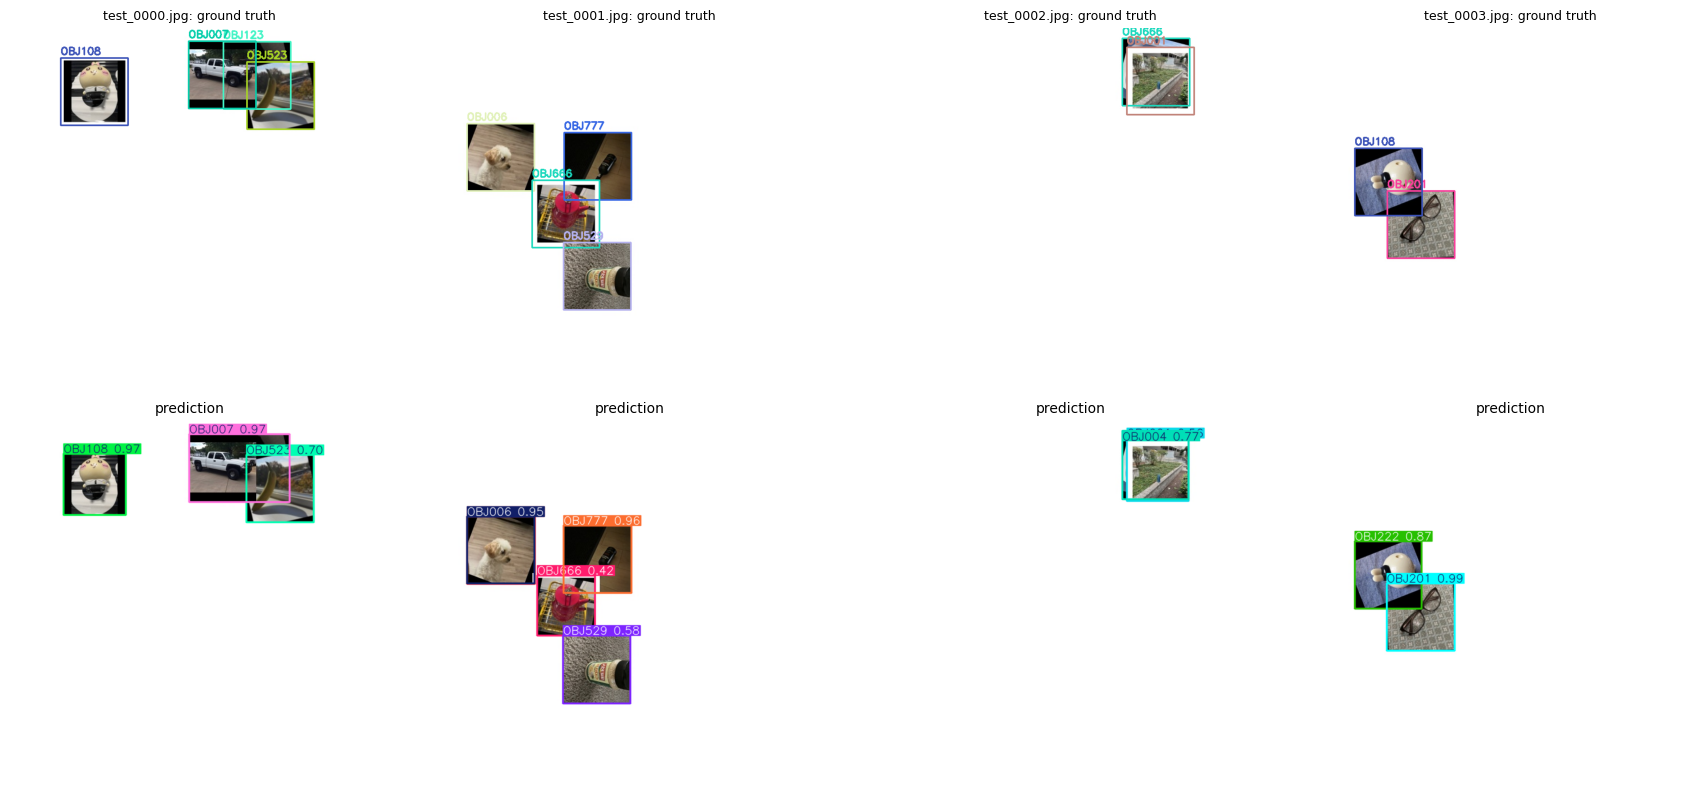

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for k, p in enumerate(test_images[:4]):
    axes[0, k].imshow(draw_gt(p, "test")); axes[0, k].set_title(f"{p.name}: ground truth", fontsize=9)
    show(trained(p, imgsz=640, conf=0.25, device=DEVICE, verbose=False)[0], axes[1, k], "prediction")
    axes[0, k].axis("off")
plt.tight_layout(); plt.show()

Optionally, try it on a **new photo** that has several of our objects in it. Put the file next
to this notebook and set the name below.

---
## Summary

| step | what we did | remember |
|---|---|---|
| prepare | split the photos 80/10/10 *before* combining, write the YAML, check labels, draw true boxes | bad labels give a bad model, so look at them first; split before augmenting so test stays unseen |
| test | `model(image, conf=…, iou=…)` | `conf` filters weak boxes; `iou` controls how NMS removes duplicates |
| train | `model.train(data=…, epochs=50, imgsz=640)` | fine-tune a pretrained model; decide on **val**, report **test** once |
| score | `model.val(data=…, split=…)` | IoU → correct / wrong → precision, recall → mAP; evaluate at low `conf` |
| report | loop over `result.boxes` | `box.cls` = ID, `box.conf` = confidence, `box.xyxy` = location |

**Why the test score is honest.** We split the ~2,000 single-object photos into train / val /
test **first** (80 / 10 / 10 per class), and only then generated the combined images for each
split. So every object in a test image comes from a photo the model never saw during training,
not just the same photo pasted at a different place, rotated or flipped. An earlier version
split the *combined* images instead, which let the same photo appear in train and test and
made the test score somewhat optimistic.